# Question 1 : D'où vient la baisse du panier moyen ?

Objectif : vérifier qui a raison entre les directeurs de boutique (qui accusent les touristes) et l'équipe digitale (qui accuse le web), et identifier sur quelle part des clients le panier baisse vraiment.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Chargement des données propres
df = pd.read_csv("../data/clean/clients_clean.csv")

# Création des variables pour comparer le prochain achat au panier moyen
df["est_touriste"] = np.where(df["pays_residence"] != df["pays_boutique"], "Touriste", "Local")
df["ecart_panier"] = df["montant_prochain_achat_eur"] - df["panier_moyen_eur"]
df["variation_pct"] = (df["ecart_panier"] / df["panier_moyen_eur"]) * 100
df["en_recul"] = df["ecart_panier"] < 0

print("Nombre de clients :", len(df))
print(f"Clients en recul : {df['en_recul'].sum()} / {len(df)} ({df['en_recul'].mean()*100:.1f} %)")
print(f"Écart moyen : {df['ecart_panier'].mean():.1f} € | Écart médian : {df['ecart_panier'].median():.1f} €")
print(f"Variation médiane : {df['variation_pct'].median():.1f} %")


Nombre de clients : 700
Clients en recul : 538 / 700 (76.9 %)
Écart moyen : -671.2 € | Écart médian : -478.0 €
Variation médiane : -23.1 %


## 1. Vérification des deux hypothèses : Touristes vs Web

Comme il y a quelques très gros paniers (jusqu'à 12 685 €) qui tirent la moyenne, on regarde la moyenne et la médiane.


In [2]:
def resume_groupe(data, colonne):
    res = data.groupby(colonne).agg(
        nb_clients=("client_id", "count"),
        panier_moyen=("panier_moyen_eur", "mean"),
        prochain_achat=("montant_prochain_achat_eur", "mean"),
        ecart_moyen=("ecart_panier", "mean"),
        ecart_median=("ecart_panier", "median"),
        variation_mediane_pct=("variation_pct", "median"),
        pct_en_recul=("en_recul", "mean")
    )
    res["part_pct"] = (res["nb_clients"] / len(data) * 100).round(1)
    res["pct_en_recul"] = (res["pct_en_recul"] * 100).round(1)
    return res.round(1)

print("--- Par profil géographique ---")
display(resume_groupe(df, "est_touriste"))

print("--- Par canal préféré ---")
display(resume_groupe(df, "canal_prefere"))

print("--- Croisement canal x touriste ---")
display(resume_groupe(df, ["canal_prefere", "est_touriste"]))


--- Par profil géographique ---


,nb_clients,panier_moyen,prochain_achat,ecart_moyen,ecart_median,variation_mediane_pct,pct_en_recul,part_pct
est_touriste,,,,,,,,
Local,151,2512.2,1933.4,-578.8,-441.0,-22.4,75.5,21.6
Touriste,549,2679.2,1982.6,-696.6,-485.0,-23.3,77.2,78.4


--- Par canal préféré ---


,nb_clients,panier_moyen,prochain_achat,ecart_moyen,ecart_median,variation_mediane_pct,pct_en_recul,part_pct
canal_prefere,,,,,,,,
boutique,404,2614.5,1947.4,-667.1,-476.5,-22.9,79.0,57.7
en ligne,157,2664.9,1997.0,-667.9,-500.0,-23.8,75.8,22.4
mixte,139,2702.1,2015.2,-686.9,-485.0,-23.3,71.9,19.9


--- Croisement canal x touriste ---


nb_clients  panier_moyen  prochain_achat  \
canal_prefere est_touriste                                             
boutique      Local                 93        2354.5          1805.4   
              Touriste             311        2692.2          1989.9   
en ligne      Local                 39        2933.0          2180.3   
              Touriste             118        2576.3          1936.4   
mixte         Local                 19        2420.5          2052.8   
              Touriste             120        2746.7          2009.2   

                            ecart_moyen  ecart_median  variation_mediane_pct  \
canal_prefere est_touriste                                                     
boutique      Local              -549.0        -479.0                  -23.1   
              Touriste           -702.4        -476.0                  -22.8   
en ligne      Local              -752.7        -518.0                  -23.8   
              Touriste           -639.9        -470.5                  -22.5   
mixte         Local              -367.6        -268.0                  -12.0   
              Touriste           -737.5        -534.5                  -24.6   

                            pct_en_recul  part_pct  
canal_prefere est_touriste                          
boutique      Local                 75.3      13.3  
              Touriste              80.1      44.4  
en ligne      Local                 79.5       5.6  
              Touriste              74.6      16.9  
mixte         Local                 68.4       2.7  
              Touriste              72.5      17.1

## 2. Recherche du vrai segment en recul (exploration des autres variables)

Ni la géographie (-23,3 % vs -22,4 %) ni le canal (-22,9 % en boutique vs -23,8 % en ligne) n'expliquent la baisse. On explore les autres variables clients (carte de fidélité, ancienneté, retours).


In [3]:
print("--- Par carte de fidélité ---")
display(resume_groupe(df, "carte_fidelite"))

df["segment"] = np.select(
    [
        df["carte_fidelite"] == "or",
        (df["carte_fidelite"] != "or") & (df["anciennete_mois"] <= 28),
        (df["carte_fidelite"] != "or") & (df["anciennete_mois"] > 28)
    ],
    [
        "Carte Or",
        "Hors Carte Or (<= 28 mois)",
        "Hors Carte Or (> 28 mois)"
    ],
    default="Autre"
)

print("--- Par segment Fidélité x Ancienneté ---")
display(resume_groupe(df, "segment"))


--- Par carte de fidélité ---


,nb_clients,panier_moyen,prochain_achat,ecart_moyen,ecart_median,variation_mediane_pct,pct_en_recul,part_pct
carte_fidelite,,,,,,,,
argent,242,2655.6,1839.0,-816.6,-574.0,-27.8,83.5,34.6
aucune,336,2568.8,1823.7,-745.1,-549.0,-26.9,83.6,48.0
inconnue,21,2648.6,1848.5,-800.1,-603.0,-22.6,81.0,3.0
or,101,2859.6,2809.5,-50.1,206.0,9.6,37.6,14.4


--- Par segment Fidélité x Ancienneté ---


,nb_clients,panier_moyen,prochain_achat,ecart_moyen,ecart_median,variation_mediane_pct,pct_en_recul,part_pct
segment,,,,,,,,
Carte Or,101,2859.6,2809.5,-50.1,206.0,9.6,37.6,14.4
Hors Carte Or (<= 28 mois),342,3171.6,2116.0,-1055.6,-852.0,-31.2,88.6,48.9
Hors Carte Or (> 28 mois),257,1855.0,1451.3,-403.7,-370.0,-20.4,76.7,36.7


## 3. Graphiques et conclusion


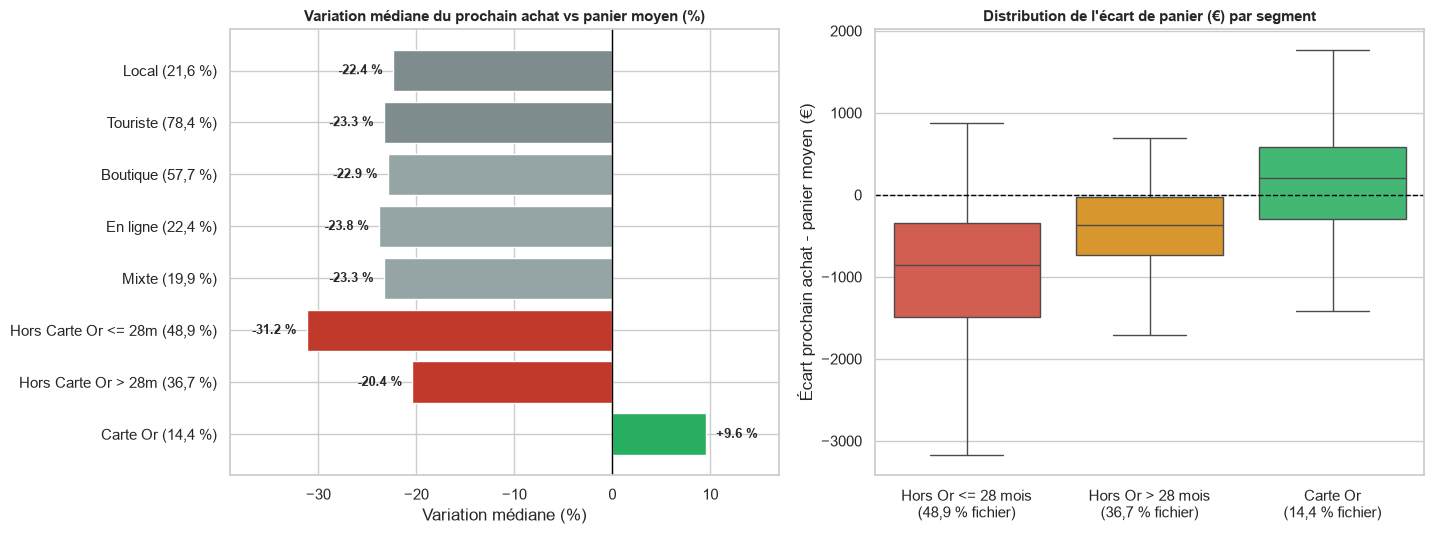

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

# Graphique 1 : Variation médiane (%) selon chaque hypothèse
comparaison = pd.DataFrame({
    "Categorie": [
        "Local (21,6 %)", "Touriste (78,4 %)",
        "Boutique (57,7 %)", "En ligne (22,4 %)", "Mixte (19,9 %)",
        "Hors Carte Or <= 28m (48,9 %)", "Hors Carte Or > 28m (36,7 %)", "Carte Or (14,4 %)"
    ],
    "Groupe": [
        "Geo", "Geo",
        "Canal", "Canal", "Canal",
        "Fidelite", "Fidelite", "Fidelite"
    ],
    "Variation_mediane_pct": [
        df.loc[df["est_touriste"] == "Local", "variation_pct"].median(),
        df.loc[df["est_touriste"] == "Touriste", "variation_pct"].median(),
        df.loc[df["canal_prefere"] == "boutique", "variation_pct"].median(),
        df.loc[df["canal_prefere"] == "en ligne", "variation_pct"].median(),
        df.loc[df["canal_prefere"] == "mixte", "variation_pct"].median(),
        df.loc[df["segment"] == "Hors Carte Or (<= 28 mois)", "variation_pct"].median(),
        df.loc[df["segment"] == "Hors Carte Or (> 28 mois)", "variation_pct"].median(),
        df.loc[df["segment"] == "Carte Or", "variation_pct"].median(),
    ]
})

palette = {"Geo": "#7f8c8d", "Canal": "#95a5a6", "Fidelite": "#c0392b"}
colors = [palette[g] if v < 0 else "#27ae60" for g, v in zip(comparaison["Groupe"], comparaison["Variation_mediane_pct"])]

bars = axes[0].barh(comparaison["Categorie"], comparaison["Variation_mediane_pct"], color=colors)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlim(-39, 17)
axes[0].invert_yaxis()
axes[0].set_title("Variation médiane du prochain achat vs panier moyen (%)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Variation médiane (%)")
for bar in bars:
    w = bar.get_width()
    axes[0].text(w + (1.0 if w >= 0 else -1.0), bar.get_y() + bar.get_height()/2, f"{w:+.1f} %",
                 va="center", ha="left" if w >= 0 else "right", fontsize=9, fontweight="bold")

# Graphique 2 : Écart en € par segment
ordre_seg = ["Hors Carte Or (<= 28 mois)", "Hors Carte Or (> 28 mois)", "Carte Or"]
sns.boxplot(
    data=df,
    x="segment",
    y="ecart_panier",
    hue="segment",
    order=ordre_seg,
    palette=["#e74c3c", "#f39c12", "#2ecc71"],
    legend=False,
    ax=axes[1],
    showfliers=False
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Distribution de l'écart de panier (€) par segment", fontsize=11, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Écart prochain achat - panier moyen (€)")
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(["Hors Or <= 28 mois\n(48,9 % fichier)", "Hors Or > 28 mois\n(36,7 % fichier)", "Carte Or\n(14,4 % fichier)"])

plt.tight_layout()
plt.savefig("../slides/q1_analyse_panier.png", dpi=150, bbox_inches="tight")
plt.show()


### Conclusion Q1

* **Ni les boutiques ni le digital n'ont raison :** les touristes (-23,3 %) et les locaux (-22,4 %) baissent autant, tout comme les clients boutique (-22,9 %), en ligne (-23,8 %) et mixtes (-23,3 %).
* **La baisse touche les clients hors Carte Or (85,6 % du fichier) :** ils sont 83,5 % à voir leur panier baisser, alors que les clients Carte Or (14,4 % du fichier) progressent de +9,6 % (+206 € en médiane).
* **Le cœur du problème concerne les clients récents hors Carte Or (<= 28 mois) :** ils représentent 48,9 % du fichier (342 clients) et 88,6 % d'entre eux reculent, avec une baisse médiane de -31,2 % (-852 €).
